# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


**Name:** Utkrisht Suman  
**Roll number:** A24ARIU0001

For this run, I used the LFW funneled release because the deep-funneled download was unavailable. The images are cropped and resized to RGB 45×45, as in the lab. There are 10,645 images after filtering, with a seeded 80/20 train/validation split.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [1]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# Change only this line for a local setup if LFW_DATASET_PATH is not set.
LOCAL_DATASET_PATH = Path("data/lfw-deepfunneled")

print(f"Running on {DEVICE}")


Running on cpu


In [2]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend(
            [
                Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
                Path("/kaggle/input/lfw-dataset"),
            ]
        )
    candidates.extend(
        [
            LOCAL_DATASET_PATH.expanduser(),
            Path("lfw-deepfunneled"),
        ]
    )

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame(
    {
        "path": image_paths,
        "person": [path.parent.name for path in image_paths],
    }
)

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(
    lambda rows: len(rows) < 25
)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()


Dataset root: /workspace/scratch/77d7cf3d0541/data/lfw_funneled
Using 10,645 images from 5,707 people


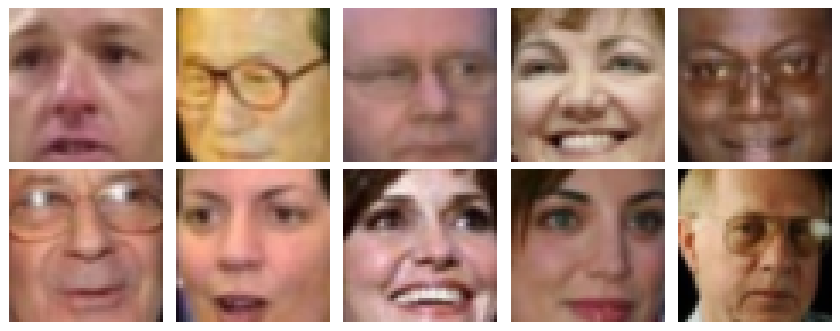

In [3]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop(
                (margin_x, margin_y, width - margin_x, height - margin_y)
            )
            return self.transform(image)


transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),  # pixel values in [0, 1]
    ]
)

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda"
)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.


## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [4]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


In [5]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [6]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    count = target.size(0)
    reconstruction_loss = (
        F.binary_cross_entropy(reconstruction, target, reduction="sum") / count
    )
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum() / count
    total = reconstruction_loss + beta * kl
    return total, reconstruction_loss.detach(), kl.detach()


In [7]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [8]:
def train_step(model, batch, optimizer, beta):
    model.train()
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    reconstruction, mu, logvar = model(batch)
    total, reconstruction_term, kl_term = vae_loss(
        reconstruction, batch, mu, logvar, beta
    )
    if not torch.isfinite(total):
        raise FloatingPointError("Nonfinite VAE loss")
    total.backward()
    optimizer.step()
    return total.item(), reconstruction_term.item(), kl_term.item()


Epoch 01 | train 3991.82 | val 3947.75 | recon 3933.31 | KL 14.44
Epoch 02 | train 3942.65 | val 3923.11 | recon 3906.25 | KL 16.87
Epoch 03 | train 3922.55 | val 3893.21 | recon 3874.02 | KL 19.20
Epoch 04 | train 3897.52 | val 3896.11 | recon 3880.80 | KL 15.31
Epoch 05 | train 3888.86 | val 3869.55 | recon 3854.66 | KL 14.88
Epoch 06 | train 3874.45 | val 3864.67 | recon 3848.86 | KL 15.81
Epoch 07 | train 3861.76 | val 3841.59 | recon 3825.78 | KL 15.80
Epoch 08 | train 3849.65 | val 3842.48 | recon 3824.16 | KL 18.32
Epoch 09 | train 3845.98 | val 3856.42 | recon 3838.79 | KL 17.62
Epoch 10 | train 3843.34 | val 3833.60 | recon 3817.65 | KL 15.95


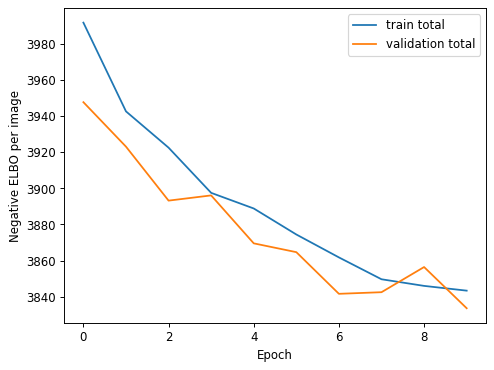

In [9]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        batch_size = batch.size(0)
        totals += np.array([value.item() for value in values]) * batch_size
        examples += batch_size
    return totals / examples


model = DenseFaceVAE().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"train_total": [], "val_total": [], "val_reconstruction": [], "val_kl": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_total = 0.0
    seen = 0
    for batch in train_loader:
        total, reconstruction_term, kl_term = train_step(model, batch, optimizer, BETA)
        running_total += total * batch.size(0)
        seen += batch.size(0)

    val_total, val_reconstruction, val_kl = evaluate(model, val_loader, BETA)
    history["train_total"].append(running_total / seen)
    history["val_total"].append(val_total)
    history["val_reconstruction"].append(val_reconstruction)
    history["val_kl"].append(val_kl)
    print(
        f"Epoch {epoch:02d} | train {running_total / seen:.2f} | "
        f"val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}"
    )

plt.plot(history["train_total"], label="train total")
plt.plot(history["val_total"], label="validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.legend()
plt.show()


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.


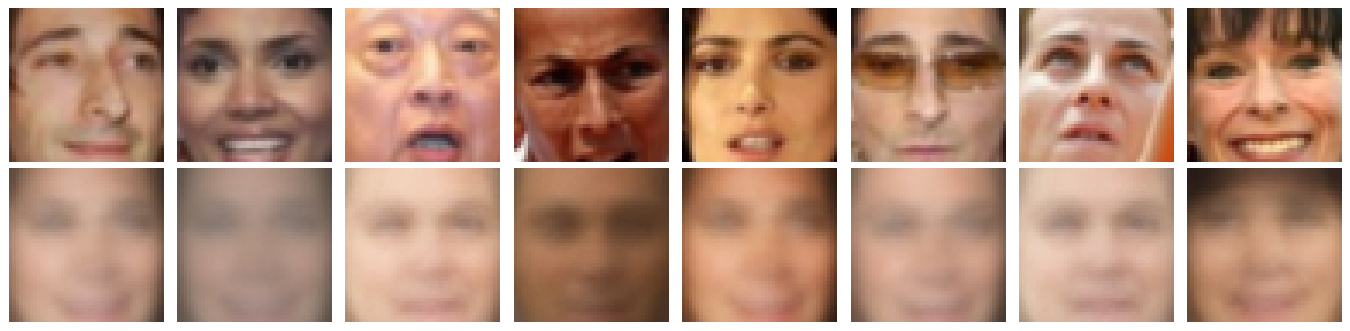

In [10]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for index in range(8):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [11]:
model.eval()
with torch.no_grad():
    z = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = model.decode(z)


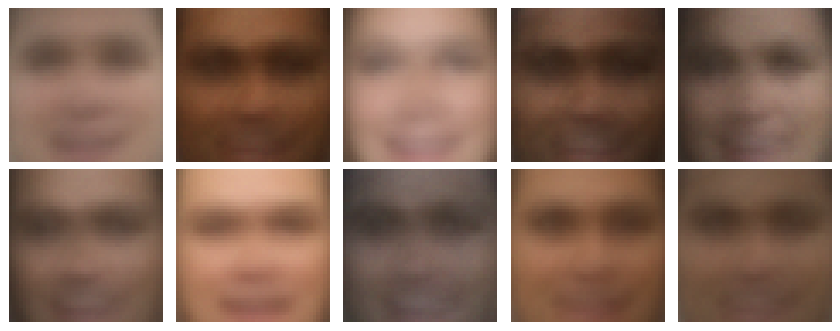

In [12]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()


## 8. Experiment: what does $\beta$ control? (15–30 minutes)

Train fresh models using two of `BETA = 0`, `0.1`, `1`, or `4`, keeping all other
settings fixed. Record validation reconstruction, validation KL, and visual quality
of prior samples.

| $\beta$ | Reconstruction | KL | Prior-sample observations |
|---:|---:|---:|---|
| 0 | 3810.85 | 268.54 | Mostly dark faces, with little variation |
| 1 | 3829.36 | 14.15 | More variation in face shape and colour, but still blurred |

Answer in a Markdown cell:

1. What happens at $\beta=0$, and why is that model no longer encouraged to have a
   sampleable unit-normal latent space?
2. How does increasing $\beta$ change reconstruction fidelity and prior samples?
3. Why can a VAE be implemented without convolutional layers? What disadvantage does
   this dense model have for images?

### Optional extensions

- Interpolate between the posterior means of two validation faces and decode the path.
- Replace the dense encoder/decoder with convolutional layers without changing the
  probabilistic heads, reparameterization, or loss.
- Add KL warm-up: increase $\beta$ gradually from 0 to 1 during early epochs.


## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**


## Answers

1. `mu`, `logvar`, and `z` each have shape `(N, 100)`. The mean can be negative, and a negative log variance represents a variance below one, so the two output heads should not use ReLU.
2. Sampling directly from the predicted distribution would interrupt ordinary backpropagation through the draw. With `z = mu + exp(0.5 * logvar) * epsilon`, the random draw is isolated in `epsilon`, while `mu` and `logvar` remain on a differentiable path.
3. With beta=0, only reconstruction is optimized. There is no penalty keeping the latent distribution close to a standard normal, so random prior samples may decode poorly.
4. Increasing beta gives more weight to KL regularization. This encourages a latent space closer to the prior, but too much regularization can reduce detail or cause posterior collapse. The measured comparison is below.
5. A VAE does not require convolution. Its main features are the probabilistic encoder, sampling step, decoder, and ELBO loss. The dense model flattens the image, so it loses the useful spatial structure that convolutions preserve and uses many parameters.

## Beta experiment

The next cell trains fresh beta=0 and beta=1 models with the same initialization, data order, ten-epoch budget, and fixed prior noise. Both validation evaluations use the same random seed.


beta=0.0, epoch=1, validation=[3937.78113601 3937.78113601   82.11756847]
beta=0.0, epoch=2, validation=[3884.93410279 3884.93410279  110.17410898]
beta=0.0, epoch=3, validation=[3867.38379239 3867.38379239  124.11072461]
beta=0.0, epoch=4, validation=[3859.01864184 3859.01864184  142.2519553 ]
beta=0.0, epoch=5, validation=[3843.96570598 3843.96570598  160.43309829]
beta=0.0, epoch=6, validation=[3837.25812109 3837.25812109  173.61640167]
beta=0.0, epoch=7, validation=[3818.31901049 3818.31901049  180.69077376]
beta=0.0, epoch=8, validation=[3811.63977332 3811.63977332  236.06338683]
beta=0.0, epoch=9, validation=[3807.09645871 3807.09645871  251.20873234]
beta=0.0, epoch=10, validation=[3810.84625734 3810.84625734  268.54456123]
beta=1.0, epoch=1, validation=[3958.27621731 3946.95188916   11.32433278]
beta=1.0, epoch=2, validation=[3917.62704119 3898.71723493   18.90980346]
beta=1.0, epoch=3, validation=[3898.66655413 3878.11273575   20.55381293]
beta=1.0, epoch=4, validation=[3881.2

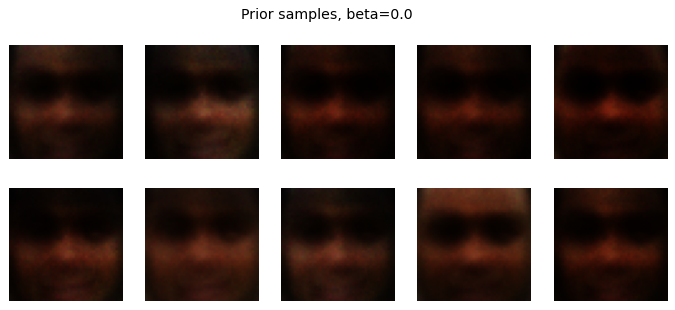

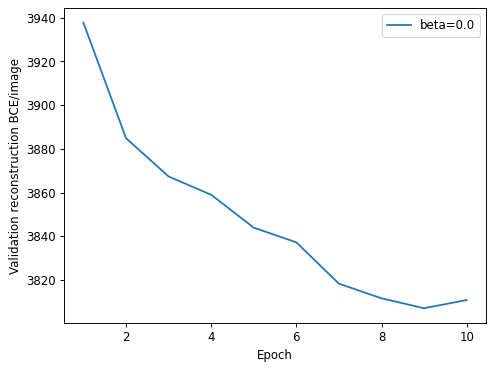

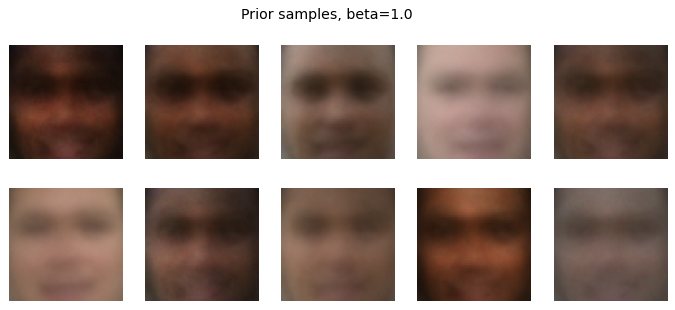

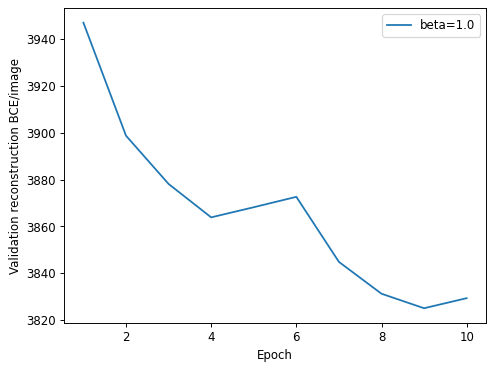

In [13]:
beta_results = []
prior_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 100)
fixed_prior = torch.randn(10, LATENT_DIM, generator=prior_rng, device=DEVICE)
for beta in (0.0, 1.0):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    experiment = DenseFaceVAE().to(DEVICE)
    opt = torch.optim.Adam(experiment.parameters(), lr=LEARNING_RATE)
    experiment_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        **loader_args,
    )
    curve = []
    for epoch in range(EPOCHS):
        experiment.train()
        for batch in experiment_loader:
            train_step(experiment, batch, opt, beta)
        with torch.random.fork_rng(
            devices=[DEVICE.index or 0] if DEVICE.type == "cuda" else []
        ):
            torch.manual_seed(SEED + 200)
            values = evaluate(experiment, val_loader, beta)
        curve.append(values)
        print(f"beta={beta}, epoch={epoch+1}, validation={values}")
    beta_results.append({"beta": beta, "reconstruction": values[1], "KL": values[2]})
    experiment.eval()
    with torch.no_grad():
        prior_faces = experiment.decode(fixed_prior).cpu()
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax, face in zip(axes.flat, prior_faces):
        ax.imshow(face.permute(1, 2, 0).clamp(0, 1))
        ax.axis("off")
    fig.suptitle(f"Prior samples, beta={beta}")
    plt.show()
    plt.plot(range(1, EPOCHS + 1), np.array(curve)[:, 1], label=f"beta={beta}")
    plt.xlabel("Epoch")
    plt.ylabel("Validation reconstruction BCE/image")
    plt.legend()
    plt.show()
print(pd.DataFrame(beta_results).to_string(index=False))


## Observations

Over ten epochs, training loss fell from 3991.82 to 3843.34 and validation loss from 3947.75 to 3833.60. The reconstructions kept the overall face shape and colour, but eyes and hair remained blurred. Samples drawn from the prior looked face-like, though they lacked fine detail.

The fresh beta=0 model reconstructed slightly better than beta=1: final reconstruction loss was 3810.85 versus 3829.36. Its KL term was much larger, at 268.54 versus 14.15, and the same prior noise produced mostly dark, similar-looking samples. Beta=1 gave more variation in face shape and colour. In this comparison, KL regularization made the prior more useful for generation at a small cost to reconstruction.

These findings come from one seed and ten epochs per model using the LFW funneled release. They show the trade-off in this experiment; choosing beta for a different dataset would need a fresh comparison.
